# Introdução

O reconhecimento automático de espécies de plantas por meio de imagens de folhas é uma importante aplicação de processamento digital de imagens e visão computacional. Antes da extração de características e da etapa de classificação, é necessário realizar um pré-processamento capaz de reduzir ruídos e destacar as informações relevantes presentes na imagem.

Neste trabalho, foram implementadas as etapas de pré-processamento, captura de características e redução de dimensionalidade destas características, descritas no EP2, utilizando ***exclusivamente*** as bibliotecas `NumPy` e `Matplotlib`. 

O pré-processamento consiste em quatro etapas principais: conversão da imagem RGB para escala de cinza, binarização, remoção de componentes de tamanhos ínfimos por meio de abertura por área e realce das bordas utilizando o gradiente morfológico interno.

A etapa de extração de características morfológicas foi estruturada em três fases principais visando uma eficiêcia de pipeline: primeiramente, criou-se um objeto **leaf**, centralizando as propriedades da folha e mitigando o custo computacional; em seguida, criou-se uma sequência de execução que explora a dependência entre as variáveis, eliminando o recálculo de funções redundantes (como o cálculo da área da folha); por fim, os resultados geométricos e morfológicos digitais foram colocados num vetor de doze dimensões ($F_{1 \times 12}$), servindo como entrada estruturada redução via PCA, descrita ulteriormente.

Finalmente, a redução de dimensionalidade foi realizada utilizando a Análise de Componentes Principais (PCA). O método elimina a correlação e redundâncias entre as características, resumindo a informação em um espaço de menor dimensão. Essa simplificação garante maior velocidade e menor consumo de recursos no treinamento e na inferência (muito importante para uma classificação massiva de árvores).


Ao longo deste relatório são apresentadas as implementações desenvolvidas, bem como exemplos dos resultados obtidos em cada etapa do processamento.

In [2]:
import numpy as np
from matplotlib import pyplot as plt
import os
import typing # somente para tipagem

/home/viktor/.venv/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


# Utilitários
Abaixo, seguem implementadas funções que não serão utilizadas diretamente na implementação do pipeline de processamento de imagem, mas que serão úteis para evitar repetição de código e para facilitar a visualização de imagens.

In [2]:
def plot_images(images):
    n = len(images)
    cols = min(5, n)
    rows = int(np.ceil(n / cols))

    fig, axes = plt.subplots(rows, cols, figsize=(3 * cols, 3 * rows))
    axes = np.atleast_1d(axes).ravel()

    for ax, img in zip(axes, images):
        ax.imshow(img, cmap="gray")
        ax.axis("off")

    for ax in axes[n:]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()


def rgb_to_gray(img: np.typing.NDArray) -> np.typing.NDArray:
    gray_scale_img = img.dot([0.2989, 0.5870, 0.1140])
    gray_scale_img = gray_scale_img / 255  # para normalizar os valores
    return gray_scale_img


def disk(radius):
    y, x = np.ogrid[-radius : radius + 1, -radius : radius + 1]
    return (x * x + y * y <= radius * radius).astype(np.uint8)


def compute_histogram(images, bins=256, value_range=(0.0, 1.0)):
    hist_total = np.zeros(bins)
    edges = None
    for img in images:
        h, edges = np.histogram(img.ravel(), bins=bins, range=value_range)
        hist_total += h
    return hist_total, edges

Para testar o código, basta atribuir à variável _images_ uma lista de imagens. 
Abaixo, a variável está utilizando as 10 primeiras imagens da pasta _Leaves_, que deve se encontrar na mesma pasta que este código. 

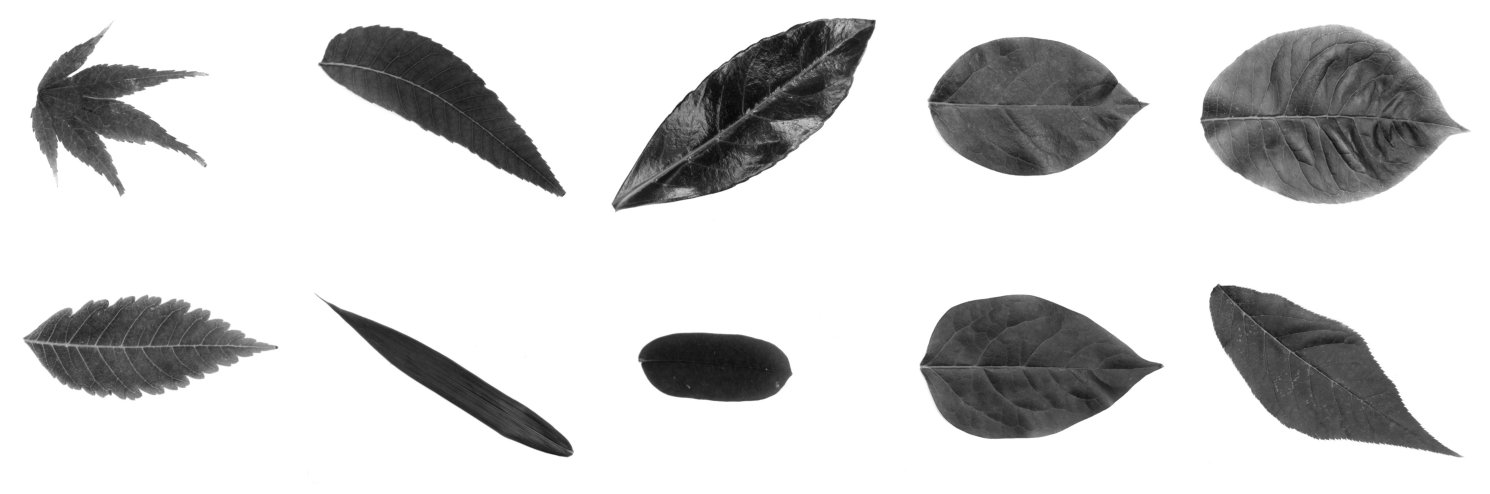

In [3]:
folder = "./Leaves"

files =[
    os.path.join(folder, file)
    for file in os.listdir(folder)
    if file.lower().endswith(".jpg")]

# Colocou-se [:10] pois o computador não tinha memória suficiente :(
all_images = np.array([plt.imread(file) for file in files[:10]])
images = all_images[:10]

gray_images = np.array(list(map(rgb_to_gray, images)))

plot_images(gray_images)

## Binarização - Determinação automática do limiar via histograma

Em vez de escolher um limiar manualmente, seguir-se-á a abordagem do paper: acumula-se o histograma de intensidades (em escala de cinza) de todas as imagens da amostra. Como as folhas são escuras e o fundo é branco, o histograma resultante apresenta dois picos bem definidos: um pico próximo de valores baixos (pixels da folha) e outro próximo de 1 (pixels do fundo branco). O limiar ideal é o ponto de "vale" entre esses dois picos, pois é onde a separação entre folha e fundo é mais nítida.

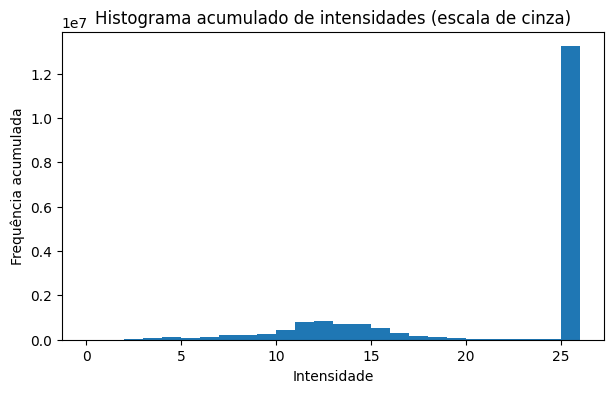

In [4]:
# --- Acumula o histograma sobre todas as imagens em escala de cinza ---
n_bins = 26
hist = np.zeros(n_bins)

for img in all_images[:10]:
    gray = rgb_to_gray(img)

    h, _ = np.histogram(gray, bins=n_bins, range=(0, 1))
    hist += h

bin_edges = np.arange(n_bins+1)
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
bin_width = bin_edges[1] - bin_edges[0]
# --- Visualização do histograma acumulado em barras ---
plt.figure(figsize=(7, 4))
plt.bar(bin_centers, hist, width=bin_width)
plt.title("Histograma acumulado de intensidades (escala de cinza)")
plt.xlabel("Intensidade")
plt.ylabel("Frequência acumulada")
plt.show()

Escolheu-se, portanto, um limiar com valor 0.93 para realizar a binarização das imagens. Esse valor mostrou-se rasoável devido ao fundo das imagens, que é branco. 

Dessa forma, um valor de 0.93 permite uma captura quase total da folha, enquanto permite possíveis ruídos no fundo, como um leve ruído gaussiano, naturalmente ocorrido durante a captura de imagens por câmeras.

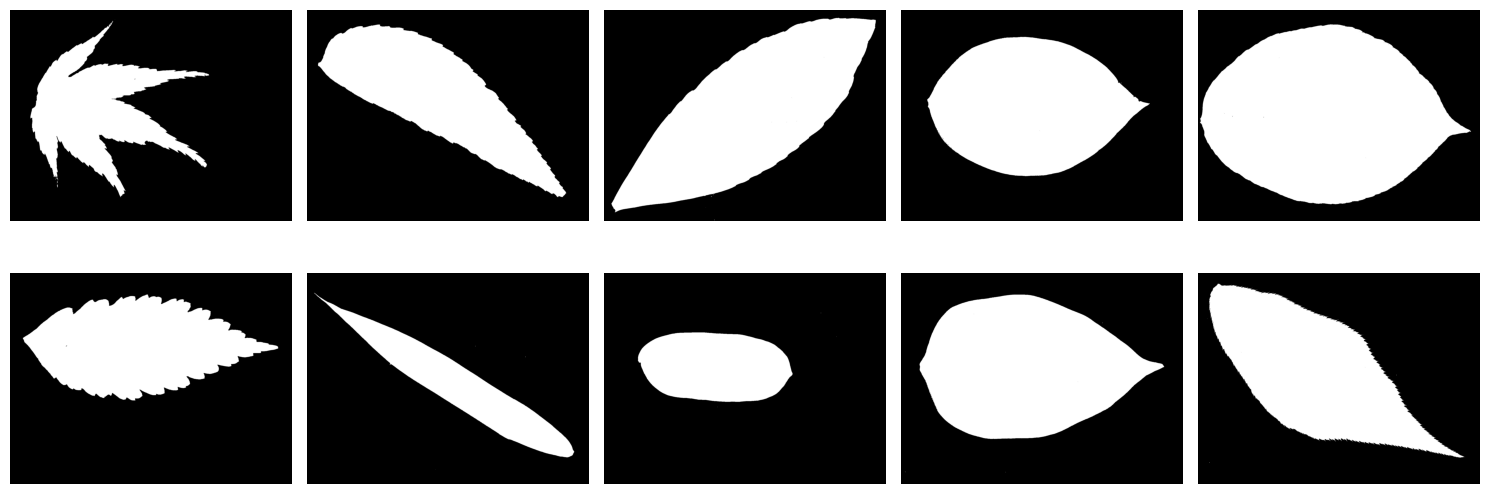

In [5]:
binary_images = np.array(list(map(lambda x: x<0.93,gray_images))).astype(int)

plot_images(binary_images)

# Operações morfológicas
A seguir, apresentam-se a implementação de uma operação morfológica genérica e as operações de abertura e fechamento, feitas a partir dessa implementação. Como laços em Python possuem desempenho relativamente baixo, buscou-se otimizar a execução utilizando operações vetorizadas do NumPy, implementadas em C. Dessa forma, em vez de percorrer os elementos da imagem com laços aninhados, são utilizadas funções como _np.maximum_ e _np.minimum_, reduzindo colossalmente o tempo de execução.

Portanto, para uma imagem de dimensão *1200×1600* e uma janela de *31×31*, a implementação da dilatação executou em aproximadamente 2,3 segundos, representando uma redução significativa em relação à implementação ingênua, que demandava cerca de 7 minutos.

In [6]:
# Usando o np.maximum ou o np.minimum consegue-se economizar bastantes laços em Python :)
# Sem estas funções, demoraria horas para calcular tudo para todas as folhas
# https://numpy.org/devdocs/reference/generated/numpy.maximum.html
# https://numpy.org/devdocs/reference/generated/numpy.minimum.html
def morphology(img, window, op, init_value, pad_value):
    h_img, w_img = img.shape
    h_win, w_win = window.shape

    pad_h = h_win // 2
    pad_w = w_win // 2

    # cria uma moldura para a imagem com o valor pad_value
    padded = np.pad(
        img,
        ((pad_h, pad_h), (pad_w, pad_w)),
        mode="constant",
        constant_values=pad_value,
    )

    res = np.full_like(img, init_value)

    for k in range(h_win):
        for l in range(w_win):
            if window[k, l]:
                op(res, padded[k : k + h_img, l : l + w_img], out=res)

    return res


def erosion(img,kernel):
    eroded = morphology(img, kernel, np.minimum, init_value=1, pad_value=1)
    return eroded

# Apenas para evitar repetir código
def opening(img, kernel):
    eroded = morphology(img, kernel, np.minimum, init_value=1, pad_value=1)
    return morphology(eroded, kernel, np.maximum, init_value=0, pad_value=0)

# Talvez seja usada no futuro
def closing(img, kernel):
    dilated =  morphology(img, kernel, np.maximum, init_value=0, pad_value=0)
    eroded = morphology(dilated, kernel, np.minimum, init_value=1, pad_value=1)
    return eroded

# Operações por Área

A seguir, é apresentada a implementação da abertura por área, utilizada para remover componentes conexos pequenos introduzidos durante a etapa de binarização. Essa operação tem como objetivo eliminar pequenos ruídos da imagem, preservando a folha para que a etapa de detecção de bordas produza resultados mais precisos.

Nesta implementação, foi adotada a conectividade-8, pois ela considera também os vizinhos diagonais como pertencentes ao mesmo componente conexo. Essa escolha é adequada para imagens de folhas, cujos contornos frequentemente apresentam conexões diagonais (principalmente folhas com muitos detalhes), evitando que partes da folha sejam indevidamente separadas durante o processamento.

In [ ]:
def area_opening(img: np.ndarray, min_area: int) -> np.ndarray:
    h, w = img.shape

    # Encontrar runs de 1s em cada linha, de forma vetorizada
    padded = np.zeros((h, w + 2), dtype=img.dtype)
    padded[:, 1:-1] = img
    d = np.diff(padded, axis=1)  # +1 no inicio de um run, -1 no fim (exclusivo)

    row_runs = []
    parent = [0]  # union-find (indice 0 nao usado)

    def find(x):
        root = x
        while parent[root] != root:
            root = parent[root]
        while parent[x] != root:
            parent[x], x = root, parent[x]
        return root

    def union(a, b):
        ra, rb = find(a), find(b)
        if ra != rb:
            parent[ra] = rb

    next_label = 1
    prev_runs = []

    for y in range(h):
        starts = np.where(d[y] == 1)[0]
        ends = np.where(d[y] == -1)[0]

        cur_runs = []
        for s, e in zip(starts, ends):
            label = next_label
            next_label += 1
            parent.append(label)
            cur_runs.append((s, e, label))

        # unir com runs da linha anterior que se sobrepoem em coluna
        pi = 0
        for s, e, label in cur_runs:
            while pi < len(prev_runs) and prev_runs[pi][1] <= s:
                pi += 1
            k = pi
            while k < len(prev_runs) and prev_runs[k][0] < e:
                union(label, prev_runs[k][2])
                k += 1

        row_runs.append(cur_runs)
        prev_runs = cur_runs

    # Somar area por componente (raiz do union-find)
    areas = {}
    for cur_runs in row_runs:
        for s, e, label in cur_runs:
            root = find(label)
            areas[root] = areas.get(root, 0) + (e - s)

    keep = {root for root, area in areas.items() if area >= min_area}

    # Reconstruir a imagem apenas com os componentes mantidos
    result = np.zeros((h, w), dtype=img.dtype)
    for y, cur_runs in enumerate(row_runs):
        row_out = result[y]
        for s, e, label in cur_runs:
            if find(label) in keep:
                row_out[s:e] = 1

    return result

Em seguida, aplica-se a operação de abertura por área, visando remover vestígios indesejados da binarização. Como critério de remoção, buscou-se utilizar um limiar relativamente grande (101 pixels) para a área mínima, uma vez que a folha, após a binarização, comporta-se como um componente grande, ocupando a maior parte da imagem.

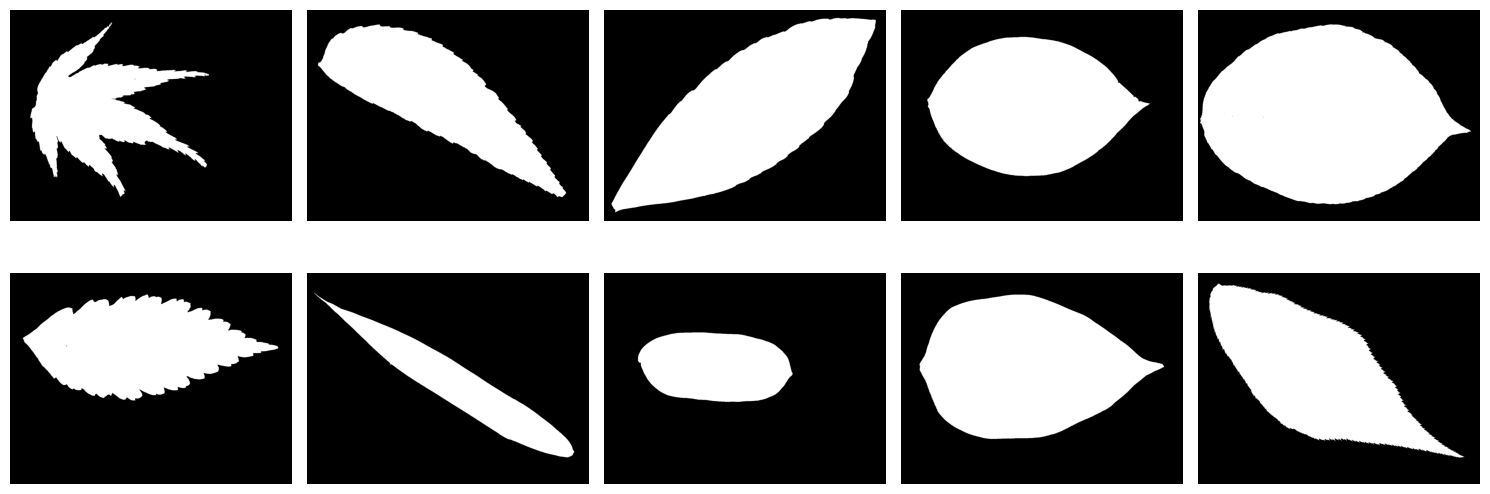

In [8]:
area_opened_images = [area_opening(img, 101) for img in binary_images]

plot_images(area_opened_images)

Acima, pode-se observar a folha após a operação de abertura por área. Nota-se a retirada das falhas deixadas pela limiarização.

# Extração de Bordas

Agora, extrair-se-ão as bordas das folhas. Para isso, utilizar-se-á o gradiente morfológico interno, o qual faz uso da operação de erosão. Essa abordagem faz com que as bordas obtidas correspondam à região interna do objeto. Para a operação de erosão, utilizou-se uma janela de tamanho *5×5*, cujos elementos são todos iguais a um.

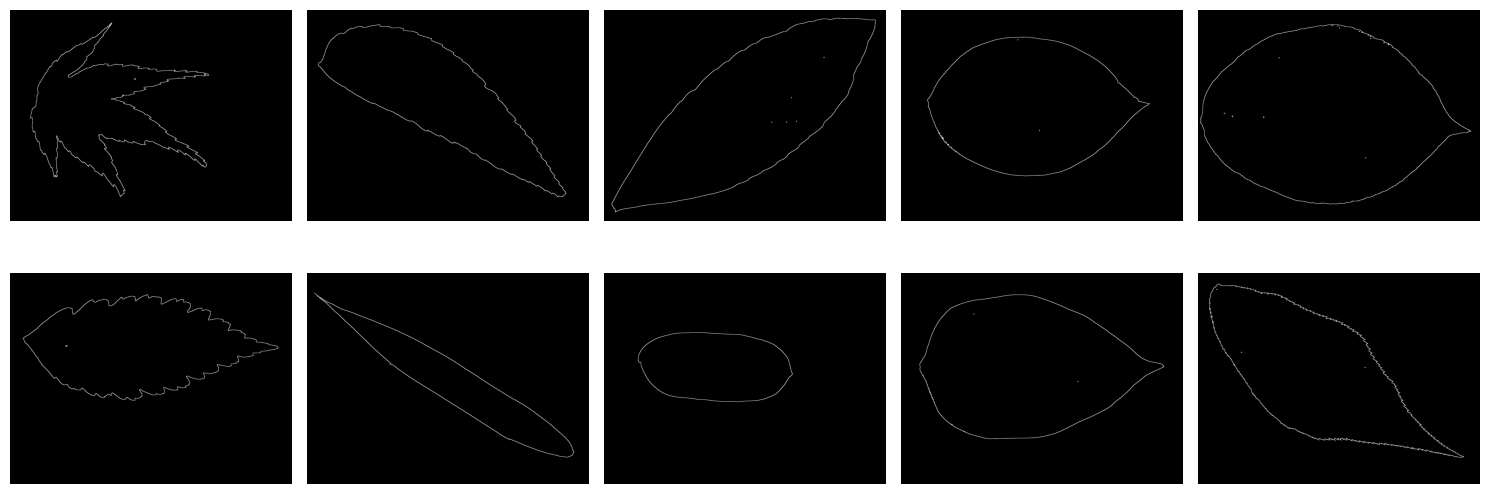

In [9]:
original_img = np.array(area_opened_images)
eroded_img = np.array([erosion(
    img, np.ones((5, 5))
) for img in original_img])
bordered_images = original_img - eroded_img

plot_images(bordered_images)

Nota-se, contudo, a presença de pequenos "buracos" no interior da folha. Esse problema pode ser mitigado por meio da aplicação de uma operação de fechamento utilizando um elemento estruturante relativamente pequeno, visto que as regiões indesejadas possuem dimensões ínfimas, tipicamente inferiores a 10 pixels.

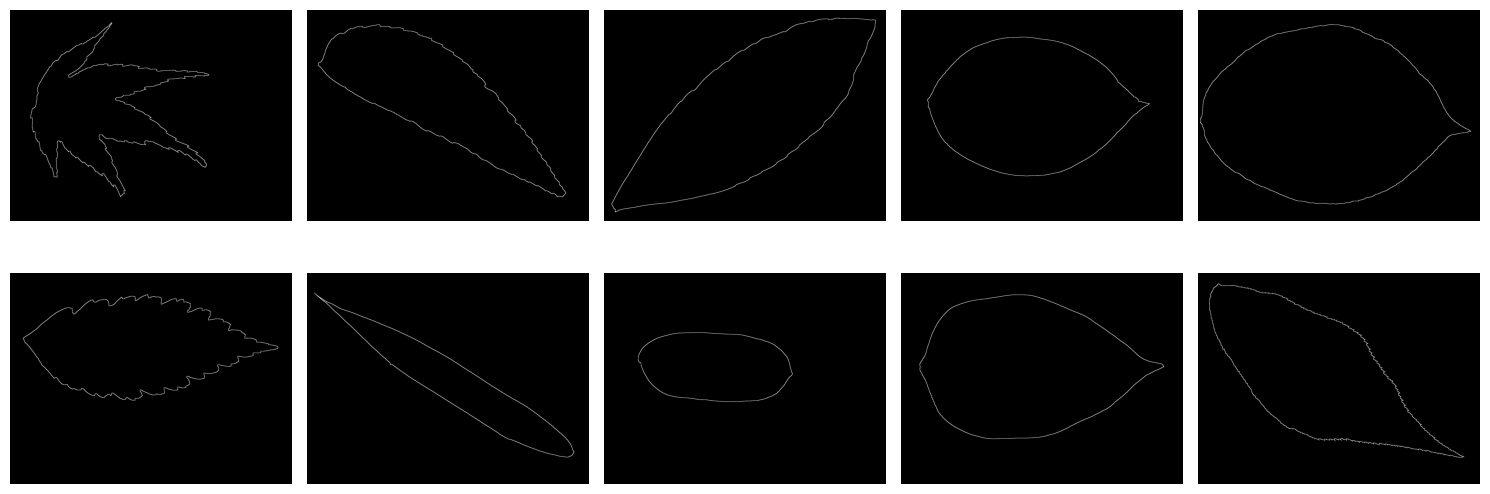

In [10]:
original_img = np.array(area_opened_images)
closing_img = np.array([closing(img,np.ones((5,5))) for img in original_img])
eroded_img = np.array([erosion(img, np.ones((5, 5))) for img in closing_img])
bordered_images = closing_img - eroded_img

plot_images(bordered_images)

Por fim, nota-se haver o pipeline para os próximos passos da identificação de espécies de plantas por meio de suas folhas.

# Segunda Parte - Extração de Características da Folha

Implementam-se, abaixo, os métodos que serão utilizados para encontrar os pontos p_1, p_2, q_1 e q_2. Buscou-se utilizar a técnica PCA, interpretando os pixels da borda como pontos no plano cartesiano. 

Novamente, visando mitigar o uso de laços em Python, implementaram-se os códigos com o auxílio do Numpy. Assim, em vez de:
```python
for i in range(len(points)):
    for j in range(i + 1, len(points)):
        p1_test = points[i]
        p2_test = points[j]

        proj = np.dot(p1_test - p2_test, eig_vec[:, 1])

        if np.isclose(proj, 0):
            p1 = p1_test
            p2 = p2_test
```

Utilizou-se o código:
```python
projections = points @ eig_vec[:, 1]

p1 = points[np.argmin(projections)]
p2 = points[np.argmax(projections)]
```

In [11]:
def calculate_eigen(X):
    # centralizar dados
    X_centered = X - np.mean(X, axis=0)

    # matriz de covariância
    C = (X_centered.T @ X_centered) / (X.shape[0] - 1)

    # autovalores e autovetores
    eig_val, eig_vec = np.linalg.eigh(C)

    # ordenar do maior para o menor autovalor
    idx = np.argsort(eig_val)[::-1]
    eig_val = eig_val[idx]
    eig_vec = eig_vec[:, idx]

    return eig_val, eig_vec


def get_leaf_eig(leaf):
    points = leaf["points"]

    eig_val, eig_vec = calculate_eigen(points)

    # ordenar do maior para o menor
    idx = np.argsort(eig_val)[::-1]
    eig_val = eig_val[idx]
    eig_vec = eig_vec[:, idx]

    return eig_val, eig_vec
    
def find_p_points(points, center, eig_vec):
    projections = (points - center) @ eig_vec[:, 0]  # só para ter certeza

    p1 = points[np.argmin(projections)]
    p2 = points[np.argmax(projections)]
    return p1, p2


def find_q_points(points, center, axis, eps=1.0):
    v1 = axis[:, 1]
    v1 /= np.linalg.norm(v1)

    # projeção de todos os pontos no eixo secundário
    t = (points - center) @ v1

    t_min = t.min()
    t_max = t.max()

    q1 = center + t_min * v1
    q2 = center + t_max * v1
    return q1, q2

Abaixo, encontram-se os métodos que calculam atributos geométricos de uma folha, como área (em pixels), diâmetro, etc.

* **Área ($A$):** Quantidade total de pixels ativos na máscara binária da folha.
    $$A = \sum_{x=1}^{M} \sum_{y=1}^{N} I_{\text{mask}}(x,y)$$
    *No código:* Implementada por `get_leaf_area(leaf)` usando `np.count_nonzero` na máscara.

* **Perímetro ($P$):** Comprimento do contorno da folha, medido pelo número de pixels na borda $B$.
    $$P = \sum_{(x,y) \in B} 1 = |B|$$
    *No código:* Implementada por `get_leaf_perimeter(leaf)` contando os pixels não nulos do contorno.

* **Diâmetro ($D$):** Maior distância euclidiana entre quaisquer dois pontos ($\mathbf{b}_i, \mathbf{b}_j$) da borda.
    $$D = \max_{i, j} \left( \| \mathbf{b}_i - \mathbf{b}_j \|_2 \right)$$
    *No código:* Obtida por `get_leaf_diameter(leaf)` amostrando os pontos da borda e buscando o maior valor de forma iterativa.

* **Comprimento Fisiológico ($L_p$):** Distância entre os pontos extremos longitudinais $\mathbf{p}_1$ e $\mathbf{p}_2$, obtidos projetando as coordenadas da borda sobre o primeiro autovetor normalizado $\mathbf{u}_1$ (direção da nervura central via PCA):
    $$\mathbf{p}_1 = \arg\min_{\mathbf{x}_i \in X} \{ \mathbf{\tilde{x}}_i \cdot \mathbf{u}_1 \}, \quad \mathbf{p}_2 = \arg\max_{\mathbf{x}_i \in X} \{ \mathbf{\tilde{x}}_i \cdot \mathbf{u}_1 \}$$
    $$L_p = \| \mathbf{p}_1 - \mathbf{p}_2 \|_2$$
    *No código:* Computado por `get_leaf_length(leaf)` através da distância euclidiana entre os dois pontos.

* **Largura Fisiológica ($W_p$):** Distância entre os pontos extremos transversais $\mathbf{q}_1$ e $\mathbf{q}_2$ (direção perpendicular ao comprimento), obtidos projetando a borda sobre o segundo autovetor normalizado $\mathbf{u}_2$:
    $$\mathbf{q}_1 = \arg\min_{\mathbf{x}_i \in X} \{ \mathbf{\tilde{x}}_i \cdot \mathbf{u}_2 \}, \quad \mathbf{q}_2 = \arg\max_{\mathbf{x}_i \in X} \{ \mathbf{\tilde{x}}_i \cdot \mathbf{u}_2 \}$$
    $$W_p = \| \mathbf{q}_1 - \mathbf{q}_2 \|_2$$
    *No código:* Computada por `get_leaf_width(leaf)` medindo a distância entre estes dois pontos ortogonais.

In [12]:
def get_leaf_area(leaf):
    # retorna a quantidade de pixels da máscara
    return np.count_nonzero(leaf["mask"])

def get_leaf_diameter(leaf):
    # lista de pontos do contorno da folha
    points = leaf["border_points"]
    D = 0
    for i in range(len(points)):
        # distância do ponto atual para todos os pontos seguintes
        d = np.linalg.norm(points[i] - points[i + 1 :], axis=1)
        if len(d):
            D = max(D, d.max())
    return D


def get_leaf_perimeter(leaf):
    # conta quantos valores não nulos há na borda
    return np.count_nonzero(leaf["border"])

def get_leaf_length(leaf):
    # retorna a distância entre p1 e p2
    return np.linalg.norm(leaf["p1"] - leaf["p2"])


def get_leaf_width(leaf):
    # retorna a distância entre q1 e q2
    return np.linalg.norm(leaf["q1"] - leaf["q2"])

A função `create_leaf` é responsável por processar uma única imagem de folha em escala de cinza e estruturar todos os seus dados. O pipeline funciona da seguinte forma:

* **Segmentação:** A imagem é binarizada com um limiar de $0.93$ para isolar a folha do fundo claro. Em seguida, `area_opening` elimina pequenos ruídos com área inferior a $101$ pixels.

* **Extração da Borda:** A borda da folha é detectada subtraindo a máscara original de sua versão erodida por um elemento estruturante de tamanho $5 \times 5$. As coordenadas dos pixels da folha e apenas da borda são organizadas em matrizes Numpy.

* **PCA:** A função calcula os autovalores e autovetores da matriz de covariância obtida a partir das coordenadas da borda, definindo, de forma automática, as direções dos nervos principal e transversal da folha.

* **Cálculo dos Terminais e Diâmetro:** Utilizando as direções do PCA, a função localiza os quatro pontos extremos da folha ($p_1$, $p_2$, $q_1$, $q_2$) para determinar o comprimento e a largura fisiológica. Por fim, calcula iterativamente o diâmetro máximo ($D$) da folha.

* **Retorno:** Todas as informações (máscaras, coordenadas, autovetores, pontos extremos e diâmetro) são organizadas e retornadas em um único dicionário para facilitar a extração posterior das características morfológicas.

Observação: Para viabilizar a automatização, a determinação dos eixos fisiológicos de comprimento ($L_p$) e largura ($W_p$) foi integrada como uma operação do objeto retornado. A partir das coordenadas dos pixels da borda da folha, o objeto calcula a matriz de covariância e extrai seus autovetores; o primeiro componente principal define a orientação do nervo central ($L_p$) e o segundo, ortogonal (pois a matriz de covariância é simétrica), determina a largura ($W_p$), eliminando o uso de marcação manual.

In [13]:
def create_leaf(gray_image):
    kernel = np.ones((5, 5))

    binary_image = (gray_image < 0.93).astype(int)
    mask = area_opening(binary_image, 101)

    border = mask - erosion(mask, kernel)

    y, x = np.nonzero(mask)
    points = np.column_stack((x, y))

    y, x = np.nonzero(border)
    border_points = np.column_stack((x, y))

    center = border_points.mean(axis=0)

    leaf = {
        "center": center,
        "mask": mask,
        "gray": gray_image,
        "border": border,
        "points": points,
        "border_points": border_points,
    }

    # Calcula PCA uma única vez
    eig_val, eig_vec = calculate_eigen(border_points)

    p1, p2 = find_p_points(points, center, eig_vec)
    q1, q2 = find_q_points(points, center, eig_vec)

    leaf.update(
        {
            "eig_val": eig_val,
            "eig_vec": eig_vec,
            "p1": p1,
            "p2": p2,
            "q1": q1,
            "q2": q2,
        }
    )
    leaf["D"] = get_leaf_diameter(leaf)
    return leaf

A função `get_central_nerves`, implementada abaixo, é responsável por extrair os eixos estruturais da folha utilizando PCA. A função devolve as coordenadas dos quatro pontos ($p_1, p_2, q_1, q_2$) que delimitam o comprimento e a largura da folha.

* **Identificação de Eixos:**

    **Eixo Longitudinal ($p_1, p_2$):** Localiza os pontos extremos ao longo da direção de máxima variância (PC1), que corresponde à extensão da nervura central.

    **Eixo Transversal ($q_1, q_2$):** Localiza os pontos extremos na direção ortogonal (PC2), definindo a largura fisiológica máxima.


In [14]:
def get_central_nerves(leaf):
    eig_val, eig_vec = get_leaf_eig(leaf)

    points = leaf["border_points"]
    center = leaf["center"]

    p1, p2 = find_p_points(points, center, eig_vec)
    q1, q2 = find_q_points(points, center, eig_vec)

    return p1, p2, q1, q2

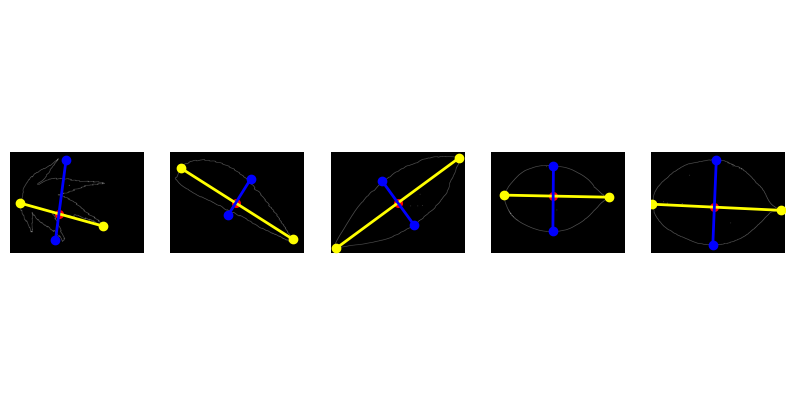

In [15]:
# Utilidade para mostrar o ponto de intersecção
def line_intersection(p1, p2, q1, q2):
    p1 = np.asarray(p1, dtype=float)
    p2 = np.asarray(p2, dtype=float)
    q1 = np.asarray(q1, dtype=float)
    q2 = np.asarray(q2, dtype=float)

    d1 = p2 - p1
    d2 = q2 - q1

    A = np.column_stack((d1, -d2))
    b = q1 - p1

    # Retas paralelas
    if np.linalg.matrix_rank(A) < 2:
        return None

    t, _ = np.linalg.solve(A, b)
    return p1 + t * d1


fig, ax = plt.subplots(1, 5, figsize=(10, 5))

for i in range(5):
    leaf = create_leaf(gray_images[i])

    eig_val, eig_vec = get_leaf_eig(leaf)
    p1, p2, q1, q2 = get_central_nerves(leaf)

    ax[i].imshow(leaf["border"], cmap="gray")

    # Segmento principal
    ax[i].plot(
        [p1[0], p2[0]],
        [p1[1], p2[1]],
        color="yellow",
        linewidth=2,
    )

    # Segmento secundário
    ax[i].plot(
        [q1[0], q2[0]],
        [q1[1], q2[1]],
        color="blue",
        linewidth=2,
    )

    # Pontos extremos
    ax[i].scatter([p1[0], p2[0]], [p1[1], p2[1]], c="yellow")
    ax[i].scatter([q1[0], q2[0]], [q1[1], q2[1]], c="blue")

    # Interseção das retas
    intersection = line_intersection(p1, p2, q1, q2)
    if intersection is not None:
        ax[i].scatter(intersection[0], intersection[1], c="red", s=30)

    ax[i].axis("equal")
    ax[i].axis("off")

plt.show()

Agora, com os pontos $p_1,p_2,q_1,q_2$ já calculados, realizar-se-ão os cálculos das métricas utilizadas para inferir a espécie da planta.

Agora, criar-se-ão funções para calcular as características morfológicas digitais.


### Implementação e Extração das Características Morfológicas

A partir das propriedades geométricas básicas extraídas e armazenadas no objeto `leaf`,como área, perímetro, diâmetro máximo, comprimento e largura fisiológicos. O pipeline calcula as doze características morfológicas da folha de forma encadeada (sem necessidade de calcular a mesma propriedade duas vezes).

Para representar a silhueta e as proporções globais, foram estruturadas funções que medem diferentes aspectos físicos da folha. O **fator de suavização** avalia a irregularidade do contorno ao comparar o tamanho da folha após erosões sucessivas com diferentes tamanhos de filtros. A proporção e o formato são capturados pelo **fator de aspecto** (relação entre comprimento e largura), pelo **fator de forma** (grau de semelhança com um círculo) e pela **retangularidade**. Adicionalmente, a relação do diâmetro máximo com as dimensões da folha e seu contorno é mapeada pelo **fator de estreitamento**, pela **razão perímetro-diâmetro** e pela **razão perímetro/medidas fisiológicas**.

Por fim, a estrutura interna das nervuras é quantificada na função de **Características de Veias**. Utilizando operações de abertura morfológica com filtros em formato de disco de diferentes raios, realiza-se uma subtração para isolar apenas os traçados das veias. A densidade de nervuras é então calculada pela proporção de pixels de veia em relação à área total da folha para cada raio analisado, gerando as quatro primeiras métricas de textura, enquanto a quinta reflete a taxa de decaimento entre a espessura máxima e mínima dessas ramificações.

In [16]:
def get_smooth_factor(leaf):
    mask_5 = erosion(leaf["mask"], np.ones((5, 5)))
    mask_3 = erosion(leaf["mask"], np.ones((3, 3)))

    A_5_5 = np.count_nonzero(mask_5)
    A_3_3 = np.count_nonzero(mask_3)

    return A_5_5 / A_3_3


def get_aspect_ratio(leaf):
    Lp = get_leaf_length(leaf)
    Wp = get_leaf_width(leaf)
    return Lp/Wp

def get_form_factor(leaf):
    A = get_leaf_area(leaf)
    P = get_leaf_perimeter(leaf)
    return 4*np.pi*A/np.square(P)


def get_rectangularity(leaf):
    Lp = get_leaf_length(leaf)
    Wp = get_leaf_width(leaf)
    A = get_leaf_area(leaf)
    return (Lp * Wp) / A


def get_narrow_factor(leaf):
    D = leaf["D"]
    Lp = get_leaf_length(leaf)
    return D / Lp


def get_perimeter_diameter_ratio(leaf):
    P = get_leaf_perimeter(leaf)
    D = leaf["D"]
    return P / D


def get_perimeter_physiological_ratio(leaf):
    P = get_leaf_perimeter(leaf)
    Lp = get_leaf_length(leaf)
    Wp = get_leaf_width(leaf)
    return P / (Lp + Wp)


DISKS = {r: disk(r) for r in [1, 2, 3, 4]}
def get_vein_features(leaf):
    gray = leaf["gray"]
    A = get_leaf_area(leaf)

    Av = []
    for r in [1, 2, 3, 4]:
        opened = opening(gray, DISKS[r])  # usa o disco pré-computado
        veins = gray - opened
        Av.append(np.count_nonzero(veins > 0))

    return (
        Av[0] / A,
        Av[1] / A,
        Av[2] / A,
        Av[3] / A,
        Av[3] / Av[0],
    )

# Criação do vetor de características
Com todos os métodos necessários criados, buscar-se-á elaborar os vetores de característica para cada folha.

Vale destacar que buscou-se otimizar ao máximo as funções. Antes da otimização, o pipeline para transformar uma imagem em um vetor de características durava cerca de 5 segundos. Dessa forma, ficaria inviável utilizar para classificação massiva de folhas.

In [17]:
def create_leaf_features(leaf):
    vein_features = get_vein_features(leaf)

    return np.array(
        [
            get_smooth_factor(leaf),
            get_aspect_ratio(leaf),
            get_form_factor(leaf),
            get_rectangularity(leaf),
            get_narrow_factor(leaf),
            get_perimeter_diameter_ratio(leaf),
            get_perimeter_physiological_ratio(leaf),
            *vein_features,
        ]
    )

## Extração de características para o conjunto completo

Aplicar-se-ão agora as funções de extração de 
características sobre a totalidade das imagens da base de dados (1907 folhas, 
correspondentes às 32 espécies descritas na tabela de plantas).

Para cada folha, obtemos um vetor com as 12 características morfológicas digitais 
(fator de suavização, proporção de aspecto, fator de forma, retangularidade, fator de 
estreitamento, razão perímetro-diâmetro, razão perímetro-medidas fisiológicas e as 5 
características de veias), resultando ao final em uma matriz de características 
$X_{1907 \times 12}$.

In [22]:
folder = "./Leaves"

features = []

filenames = sorted(f for f in os.listdir(folder) if f.lower().endswith(".jpg"))

for filename in filenames:
    img = plt.imread(os.path.join(folder, filename))
    gray_img = rgb_to_gray(img)
    leaf = create_leaf(gray_img)
    features.append(create_leaf_features(leaf))
    print(f"Feature computada para {filename}")

X = np.array(features)

Feature computada para 1001.jpg
Feature computada para 1002.jpg
Feature computada para 1003.jpg
Feature computada para 1004.jpg
Feature computada para 1005.jpg
Feature computada para 1006.jpg
Feature computada para 1007.jpg
Feature computada para 1008.jpg
Feature computada para 1009.jpg
Feature computada para 1010.jpg
Feature computada para 1011.jpg
Feature computada para 1012.jpg
Feature computada para 1013.jpg
Feature computada para 1014.jpg
Feature computada para 1015.jpg
Feature computada para 1016.jpg
Feature computada para 1017.jpg
Feature computada para 1018.jpg
Feature computada para 1019.jpg
Feature computada para 1020.jpg
Feature computada para 1021.jpg
Feature computada para 1022.jpg
Feature computada para 1023.jpg
Feature computada para 1024.jpg
Feature computada para 1025.jpg
Feature computada para 1026.jpg
Feature computada para 1027.jpg
Feature computada para 1028.jpg
Feature computada para 1029.jpg
Feature computada para 1030.jpg
Feature computada para 1031.jpg
Feature 

# Redução de dimensão
Nesta seção, buscar-se-á utilizar técnicas de álgebra linear para reduzir o número de parâmetros. Esta etapa é importante pois alguns dos parâmetros podem estar sendo redundantes, isto é, possui informações similares a outros parâmetros. 

A técnica escolhida foi o PCA (Principal Component Analysis) por ser intuitiva e rápida, característica esta que é importante para classificar grandes volumes de folhas. Portanto, o número de parâmetros será reduzido de 12 para 5.

In [3]:
def pca(X, n_components=5):
    # centralizar
    mean = np.mean(X, axis=0)
    X_centered = X - mean

    # matriz de covariância
    C = np.cov(X_centered, rowvar=False)

    # autovalores e autovetores
    eig_val, eig_vec = np.linalg.eigh(C)

    # ordenar maior para menor
    idx = np.argsort(eig_val)[::-1]
    eig_val = eig_val[idx]
    eig_vec = eig_vec[:, idx]

    # pegar os n componentes principais
    components = eig_vec[:, :n_components]

    # projetar dados
    X_pca = X_centered @ components

    return X_pca, eig_val, components

É importante normalizar os dados antes devido à diferença de magnitude entre os dados. Desta forma, o código abaixo será encarregado por normalizar a matriz X, cujo resultado será armazenado na variável **X_scaled**.

In [4]:
X = np.load("./leaf_features.npy")

In [5]:
mean = X.mean(axis=0)
std = X.std(axis=0)
std[std == 0] = 1  # evita divisão por zero se alguma coluna for constante
# utilizando as 10 primeiras imagens do dataset, o desvio padrão 
# do narrow_factor ficava em 0 e dava erro de divisão por 0 :D

X_scaled = (X - mean) / std
print("Média: ", X_scaled.mean())
print("Desvio padrão: ", X_scaled.std())

Média:  9.300024480635607e-15
Desvio padrão:  0.9999999999999999


In [6]:
X_pca, eig_val, components = pca(X_scaled, 5)

explained_variance = eig_val[:5] / eig_val.sum()

print(
    "A importância de cada dimensão é:",
    explained_variance,
    "\nTotalizando cerca de",
    explained_variance.sum() * 100,
    "% da variância original",
)
print("Formato: ",X_pca.shape)

A importância de cada dimensão é: [0.37530535 0.23530069 0.13559057 0.10379121 0.06212428] 
Totalizando cerca de 91.21121027416794 % da variância original
Formato:  (1907, 5)


In [9]:
X_pca
np.save("./leaf_features_pca.npy", X_pca)

Notavelmente, após a redução, parte da semântica dos dados foi mantida e, finalmente, obtém-se a matriz X_pca, de tamanho **1907x5** e que pode ser utilizada na próxima etapa.

Juntos, os 5 componentes principais retêm aproximadamente **91.3%** da variância total 
presente nas características originais, o que indica que a redução de 12 para 5 dimensões 
praticamente não descarta informação relevante para a discriminação entre espécies. 
Nota-se ainda que os dois primeiros componentes concentram sozinhos cerca de **61.2%** 
da variância, sugerindo que a maior parte da variabilidade entre as folhas pode ser 
capturada por poucas direções principais — provavelmente relacionadas ao formato geral 
(alongamento, retangularidade) e à textura de veias da folha.